In [1]:
import tensorflow as tf
import numpy as np

X = np.array([[0,0], [0,1], [1,0], [1,1]])#2 atributos de entrada
X

array([[0, 0],
       [0, 1],
       [1, 0],
       [1, 1]])

In [2]:
y = np.array([[0], [1], [1], [0]])
y

array([[0],
       [1],
       [1],
       [0]])

In [3]:
neuronios_entrada = 2
neuronios_oculta = 3
neuronios_saida = 1

In [4]:
W = {'oculta': tf.Variable(tf.random_normal([neuronios_entrada, neuronios_oculta]), name = 'w_oculta'), #6 pesos na matriz
     'saida': tf.Variable(tf.random_normal([neuronios_oculta, neuronios_saida]), name = 'w_saida')}#3 linhas 1 coluna

In [5]:
type(W)

dict

In [6]:
type(W['oculta'])

tensorflow.python.ops.variables.RefVariable

In [7]:
W['oculta']

<tf.Variable 'w_oculta:0' shape=(2, 3) dtype=float32_ref>

In [8]:
W['saida']

<tf.Variable 'w_saida:0' shape=(3, 1) dtype=float32_ref>

C:\Users\183134\AppData\Local\conda\conda\envs\TensorFlow\lib\site-packages\scipy\stats\stats.py:1713: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  return np.add.reduce(sorted[indexer] * weights, axis=axis) / sumval


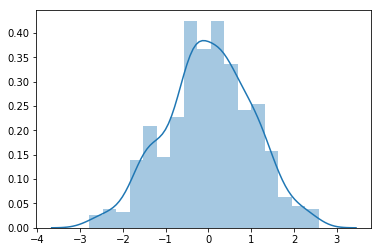

In [9]:
distribuicao = np.random.normal(size = 500)
#distribuicao
import seaborn as sns
%matplotlib inline
sns.distplot(distribuicao)

In [10]:
b = {'oculta': tf.Variable(tf.random_normal([neuronios_oculta]), name = 'b_oculta'),
     'saida': tf.Variable(tf.random_normal([neuronios_saida]), name = 'b_saida')}

In [11]:
xph = tf.placeholder(tf.float32, [4, neuronios_entrada], name = 'xph')
yph = tf.placeholder(tf.float32, [4, neuronios_saida], name = 'yph')

In [12]:
camada_oculta = tf.add(tf.matmul(xph, W['oculta']), b['oculta'])
camada_oculta_ativacao = tf.sigmoid(camada_oculta)
camada_saida = tf.add(tf.matmul(camada_oculta_ativacao, W['saida']), b['saida'])
camada_saida_ativacao = tf.sigmoid(camada_saida)
erro = tf.losses.mean_squared_error(yph, camada_saida_ativacao)
otimizador = tf.train.GradientDescentOptimizer(learning_rate = 0.3).minimize(erro)

In [13]:
init = tf.global_variables_initializer()

In [14]:
with tf.Session() as sess:
    sess.run(init)
    #print(sess.run(W['oculta']))
    #print(sess.run(W['saida']))
    #print(sess.run(b['oculta']))
    #print('\n')
    #print(sess.run(b['saida']))
    #print(sess.run(camada_oculta, feed_dict = {xph: X}))
    #print(sess.run(camada_oculta_ativacao, feed_dict = {xph: X}))
    #print(sess.run(camada_saida, feed_dict = {xph: X}))
    #print(sess.run(camada_saida_ativacao, feed_dict = {xph: X}))
    for epocas in range(10000):
        erro_medio = 0
        _, custo = sess.run([otimizador, erro], feed_dict = {xph: X, yph: y})
        if epocas % 200 == 0:
            #print(custo)
            erro_medio += custo / 4
            print(erro_medio)
    W_final, b_final = sess.run([W, b])
            #vai rodar 10000 e a cada 20 vezes ele mostra o erro médio

0.08371828496456146
0.06250710785388947
0.062077607959508896
0.06136807054281235
0.05951802805066109
0.0543675571680069
0.04262332618236542
0.026584435254335403
0.015215391293168068
0.009354494512081146
0.006336981430649757
0.004636763595044613
0.0035888529382646084
0.0028943263459950686
0.0024071589577943087
0.0020498945377767086
0.0017784562660381198
0.0015662303194403648
0.0013963478850200772
0.0012576632434502244
0.0011425516568124294
0.001045636716298759
0.0009630380081944168
0.0008918835665099323
0.0008300081826746464
0.0007757535204291344
0.0007278269622474909
0.0006852077203802764
0.0006470802472904325
0.0006127875531092286
0.0005817903438583016
0.0005536465905606747
0.0005279858596622944
0.0005045022699050605
0.00048293499276041985
0.0004630631301552057
0.00044469747808761895
0.00042767764534801245
0.00041186338057741523
0.00039713334990665317
0.0003833818482235074
0.0003705151320900768
0.0003584538062568754
0.00034712505294010043
0.0003364646981935948
0.00032641724101267755
0

In [15]:
W_final

{'oculta': array([[-5.085961  ,  0.9932879 , -5.7887816 ],
        [ 5.617726  , -0.28058153,  5.265383  ]], dtype=float32),
 'saida': array([[-7.6376934],
        [ 3.0542524],
        [ 8.772237 ]], dtype=float32)}

In [16]:
b_final

{'oculta': array([ 2.5709863e+00,  2.7271050e-03, -2.7832265e+00], dtype=float32),
 'saida': array([1.6111373], dtype=float32)}

In [17]:
# teste
camada_oculta_teste = tf.add(tf.matmul(xph, W_final['oculta']), b_final['oculta'])
camada_oculta_ativacao_teste = tf.sigmoid(camada_oculta_teste)
camada_saida_teste = tf.add(tf.matmul(camada_oculta_ativacao_teste, W_final['saida']), b_final['saida'])
camada_saida_ativacao_teste = tf.sigmoid(camada_saida_teste)

In [18]:
with tf.Session() as sess:
    sess.run(init)
    print(sess.run(camada_saida_ativacao_teste, feed_dict = {xph: X}))

[[0.03094902]
 [0.96731544]
 [0.9634496 ]
 [0.034327  ]]
